In [3]:
import numpy as np
import pandas as pd
import os
import plotly.express as px
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)

# PUT GITHUB ROOT PATH HERE
root_dir = "/Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization"
dir = root_dir + "/Data and Resources"
os.chdir(dir)
data = pd.read_csv(os.path.join(dir, "final_data.csv"))
print(data.shape)
print(data.columns)

(8984, 26)
Index(['respondent_id', 'timely_college', 'violent_victimization_18_24',
       'earliest_arrest_before_18', 'total_number_of_incarcerations',
       'r_threatened_to_be_hurt_at_school', 'r_in_a_fight_at_school',
       'days_r_absent_from_school', 'teachers_good',
       'discipline_is_fair_agree_disagree', 'percent_of_peers_who_smoke',
       'percent_of_peers_who_get_drunk_1_times_a_month',
       'percent_of_peers_belong_to_a_gang',
       'percent_of_peers_who_have_had_sex', 'bullying_victim_before_age_12',
       'r_victim_of_bullying_12_18_years', 'sex',
       'r_ever_live_through_hard_times', 'household_net_worth',
       'household_size', 'biological_father_education',
       'biological_mother_education', 'race_ethnicity',
       'asvab_math_verbal_score_percent', 'mother_serve_prison_sentence',
       'father_serve_prison_sentence'],
      dtype='str')


In [4]:
covariates = [
    col for col in data.columns
    if col not in ["respondent_id", "timely_college", "violent_victimization_18_24"]
]

outcome = "violent_victimization_18_24"

treatment = "timely_college"

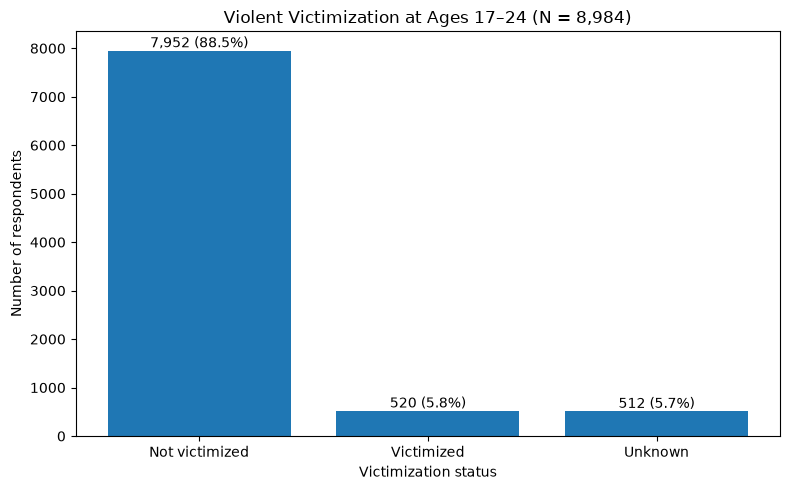

In [5]:
import matplotlib.pyplot as plt

plot_data = data.copy()

plot_data["outcome_label"] = plot_data[outcome].map({
    0: "Not victimized",
    1: "Victimized"
}).fillna("Unknown")

order = ["Not victimized", "Victimized", "Unknown"]
counts = plot_data["outcome_label"].value_counts().reindex(order, fill_value=0)
percentages = counts / len(plot_data) * 100

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(counts.index, counts.values)

for bar, count, pct in zip(bars, counts.values, percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} ({pct:.1f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title(f"Violent Victimization at Ages 17–24 (N = {len(plot_data):,})")
ax.set_xlabel("Victimization status")
ax.set_ylabel("Number of respondents")

plt.tight_layout()
plt.show()

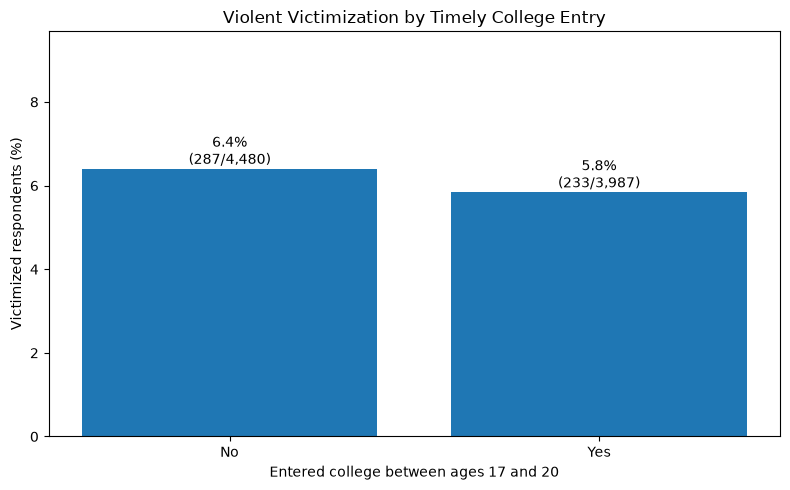

In [6]:
plot_data = data[
    data[treatment].notna()
    & data[outcome].notna()
].copy()

plot_data["college_entry"] = plot_data[treatment].map({
    0: "No",
    1: "Yes"
})

summary = (
    plot_data.groupby("college_entry")[outcome]
    .agg(["sum", "count"])
    .reindex(["No", "Yes"])
)

summary["percent_victimized"] = (
    summary["sum"] / summary["count"] * 100
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    summary.index,
    summary["percent_victimized"]
)

for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{row['percent_victimized']:.1f}%\n"
        f"({int(row['sum']):,}/{int(row['count']):,})",
        ha="center",
        va="bottom"
    )

ax.set_title("Violent Victimization by Timely College Entry")
ax.set_xlabel("Entered college between ages 17 and 20")
ax.set_ylabel("Victimized respondents (%)")
ax.set_ylim(0, min(100, summary["percent_victimized"].max() * 1.2 + 2))

plt.tight_layout()
plt.show()

In [8]:
numeric_features = [
    "total_number_of_incarcerations",
    "days_r_absent_from_school",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "household_net_worth",
    "household_size",
    "asvab_math_verbal_score_percent"
]

categorical_features = [
    "teachers_good",
    "discipline_is_fair_agree_disagree",
    "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month",
    "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex",
    "bullying_victim_before_age_12",
    "r_victim_of_bullying_12_18_years",
    "earliest_arrest_before_18",
    "sex",
    "r_ever_live_through_hard_times",
    "biological_father_education",
    "biological_mother_education",
    "race_ethnicity",
    "mother_serve_prison_sentence",
    "father_serve_prison_sentence"
]

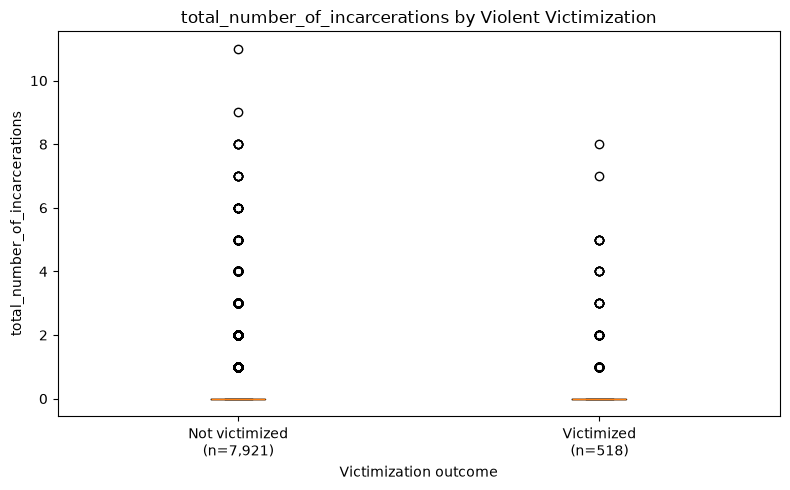

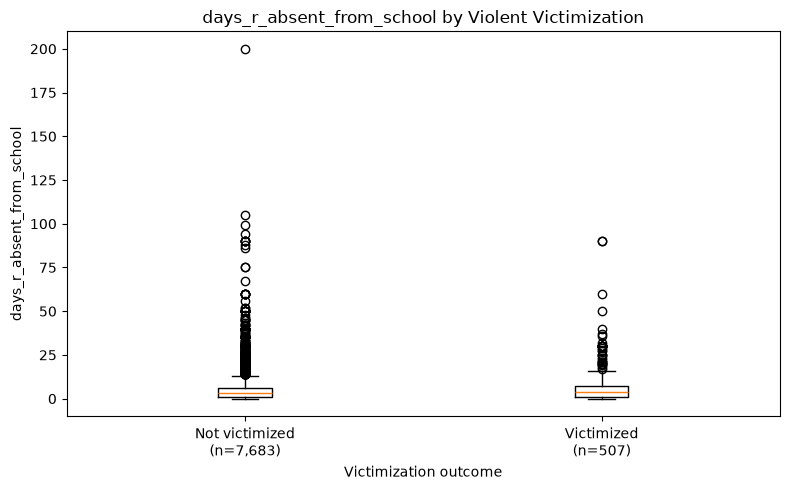

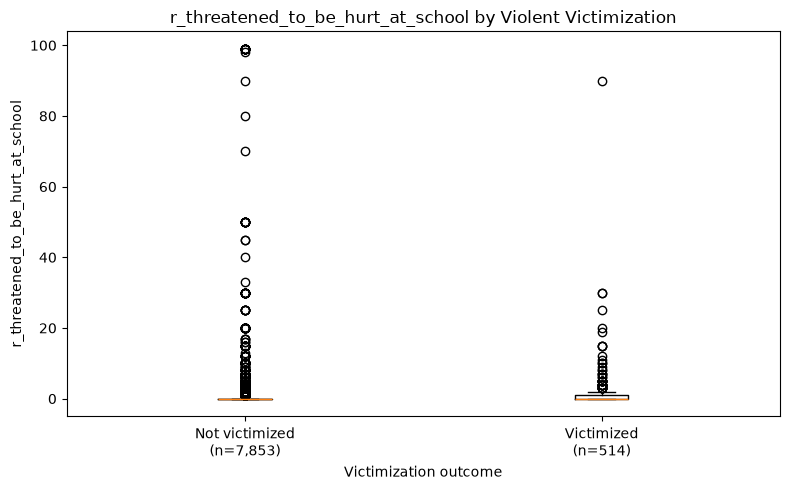

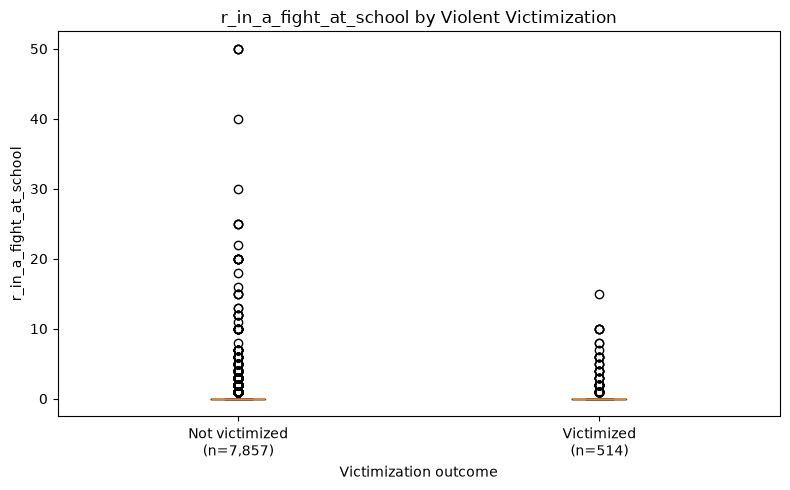

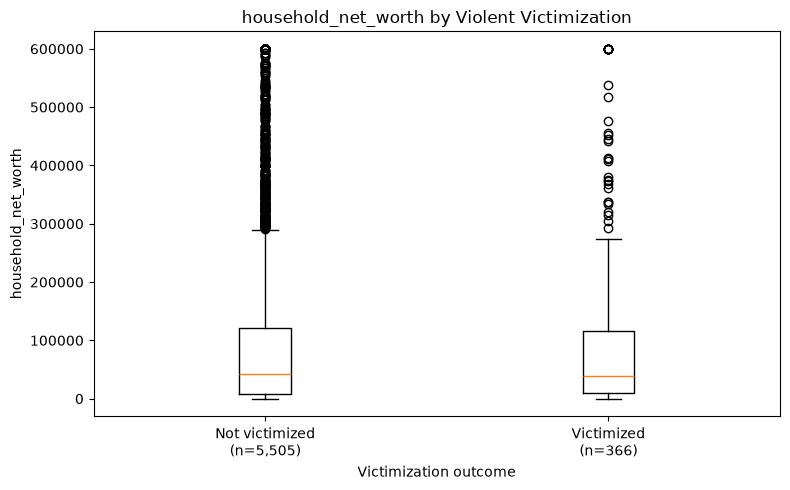

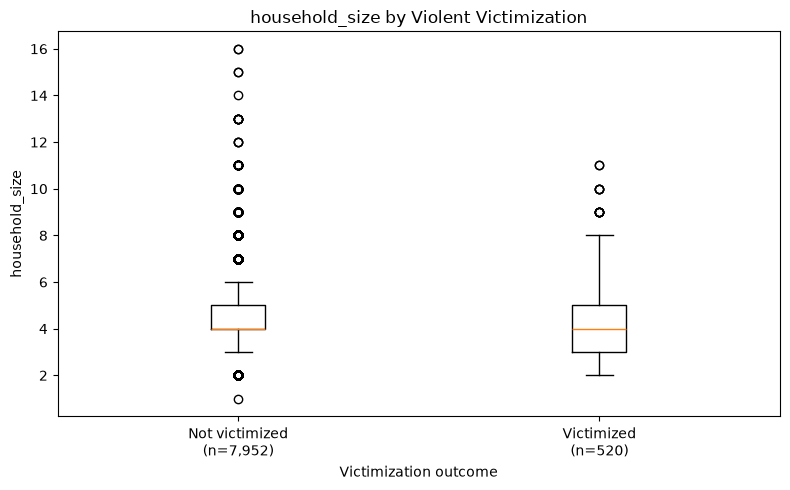

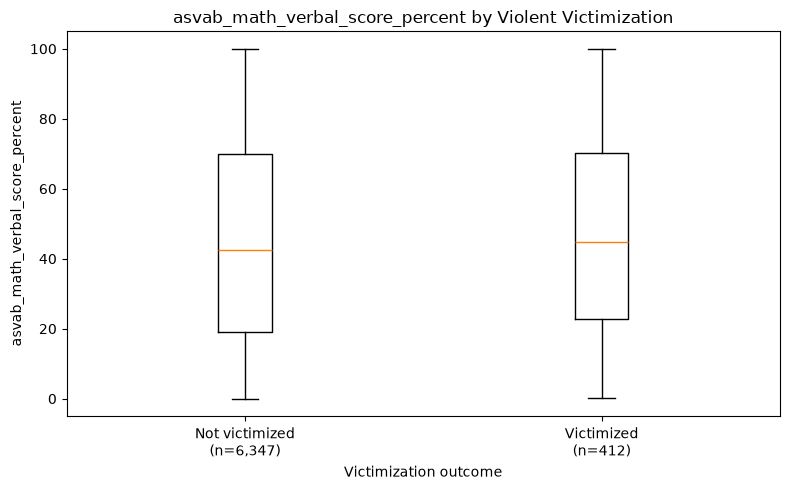

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_data = data[data[outcome].notna()].copy()

# Treat negative survey values as missing for plotting
for col in numeric_features:
    plot_data.loc[plot_data[col] < 0, col] = np.nan

for col in numeric_features:
    group_0 = plot_data.loc[plot_data[outcome] == 0, col].dropna()
    group_1 = plot_data.loc[plot_data[outcome] == 1, col].dropna()

    if group_0.empty or group_1.empty:
        continue

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.boxplot(
        [group_0, group_1],
        tick_labels=[
            f"Not victimized\n(n={len(group_0):,})",
            f"Victimized\n(n={len(group_1):,})"
        ]
    )

    ax.set_title(f"{col} by Violent Victimization")
    ax.set_xlabel("Victimization outcome")
    ax.set_ylabel(col)

    plt.tight_layout()
    plt.show()

In [12]:
# ------------------------------------------------------------
# Response code -> text (hard-coded from the NLSY97 codebook)
# ------------------------------------------------------------
AGREE_4 = {1: "Strongly agree", 2: "Agree", 3: "Disagree", 4: "Strongly disagree"}

PEERS_5 = {
    1: "Almost none (less than 10%)",
    2: "About 25%",
    3: "About half (50%)",
    4: "About 75%",
    5: "Almost all (more than 90%)",
}

YES_NO = {0: "No", 1: "Yes"}

PARENT_EDU = {
    0: "None",
    1: "1st grade", 2: "2nd grade", 3: "3rd grade", 4: "4th grade", 5: "5th grade",
    6: "6th grade", 7: "7th grade", 8: "8th grade", 9: "9th grade", 10: "10th grade",
    11: "11th grade", 12: "12th grade",
    13: "1st year college", 14: "2nd year college", 15: "3rd year college",
    16: "4th year college", 17: "5th year college", 18: "6th year college",
    19: "7th year college", 20: "8th year college or more",
    95: "Ungraded",
}

CATEGORY_LABELS = {
    "teachers_good": AGREE_4,
    "discipline_is_fair_agree_disagree": AGREE_4,
    "percent_of_peers_who_smoke": PEERS_5,
    "percent_of_peers_who_get_drunk_1_times_a_month": PEERS_5,
    "percent_of_peers_belong_to_a_gang": PEERS_5,
    "percent_of_peers_who_have_had_sex": PEERS_5,
    "bullying_victim_before_age_12": YES_NO,
    "r_victim_of_bullying_12_18_years": YES_NO,
    "earliest_arrest_before_18": YES_NO,          # derived column; assumed 0/1
    "sex": {1: "Male", 2: "Female"},
    "r_ever_live_through_hard_times": YES_NO,
    "biological_father_education": PARENT_EDU,
    "biological_mother_education": PARENT_EDU,
    "mother_serve_prison_sentence": YES_NO,
    "father_serve_prison_sentence": YES_NO,
    # race_ethnicity is already text (White/Black/Hispanic/Asian/Other): no mapping needed
}

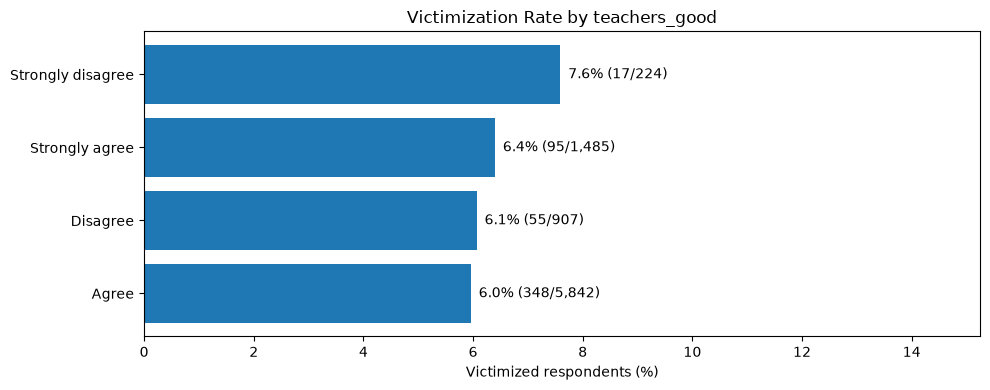

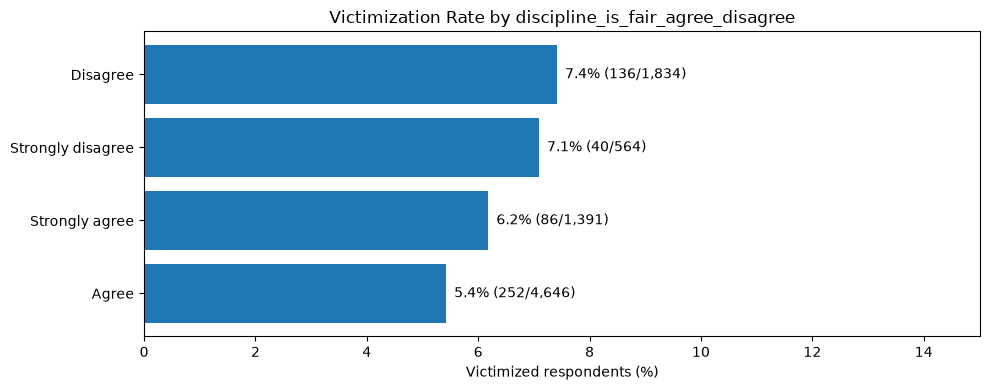

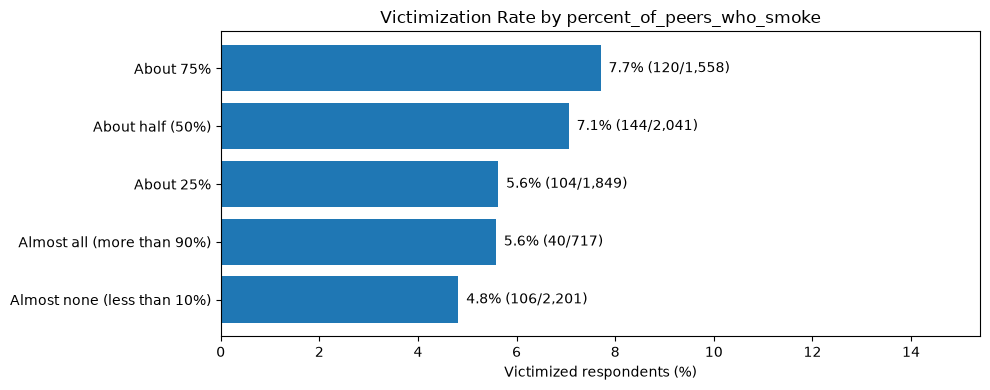

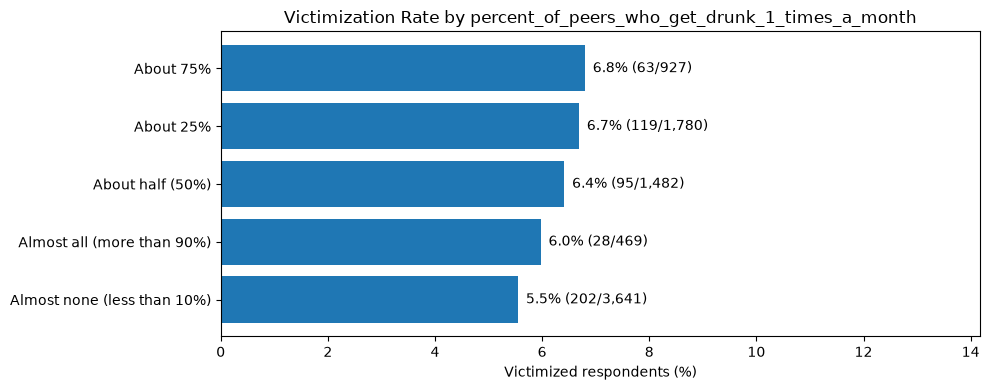

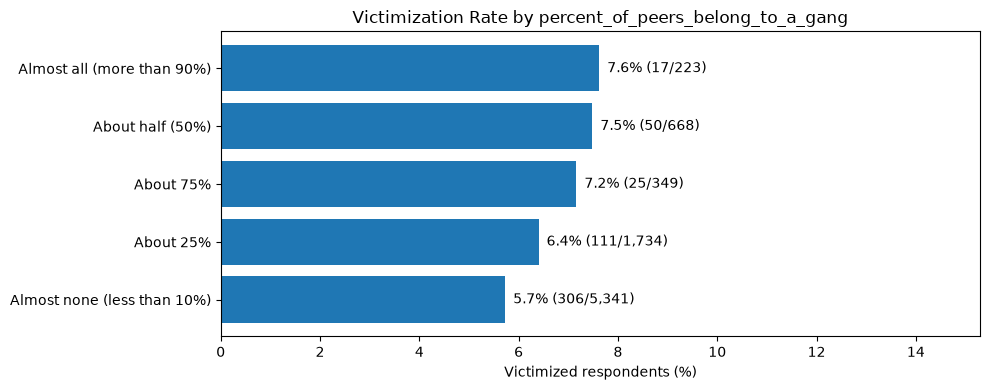

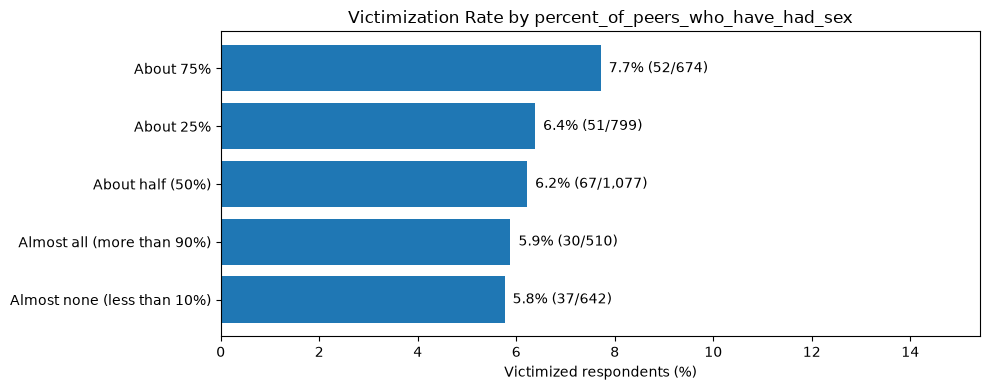

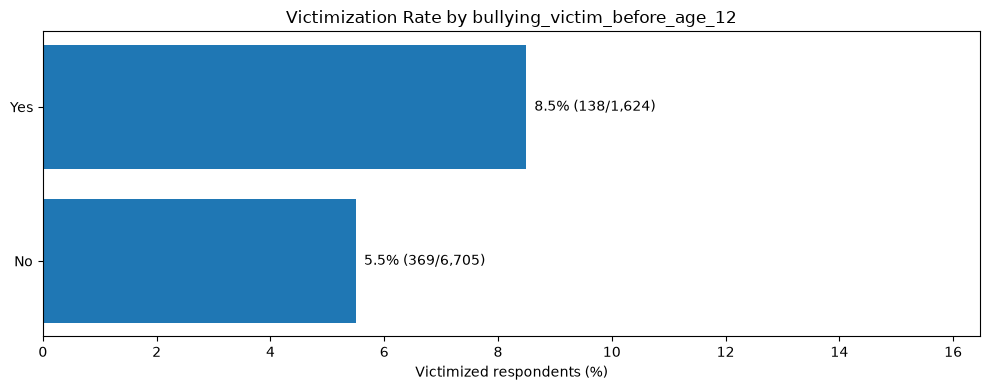

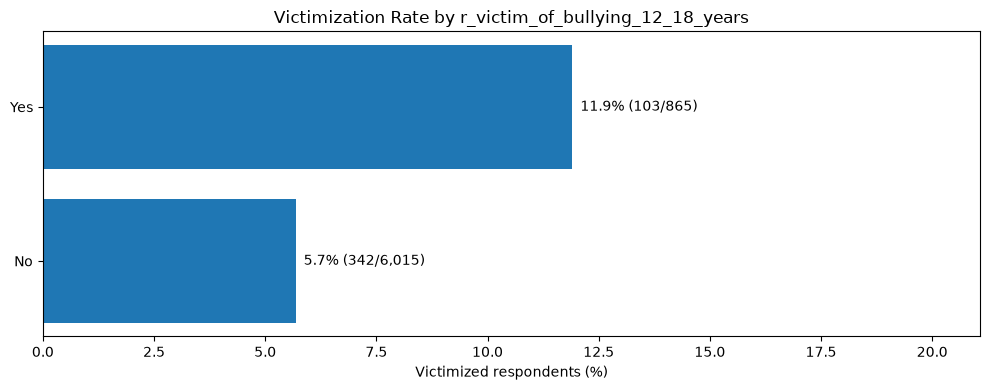

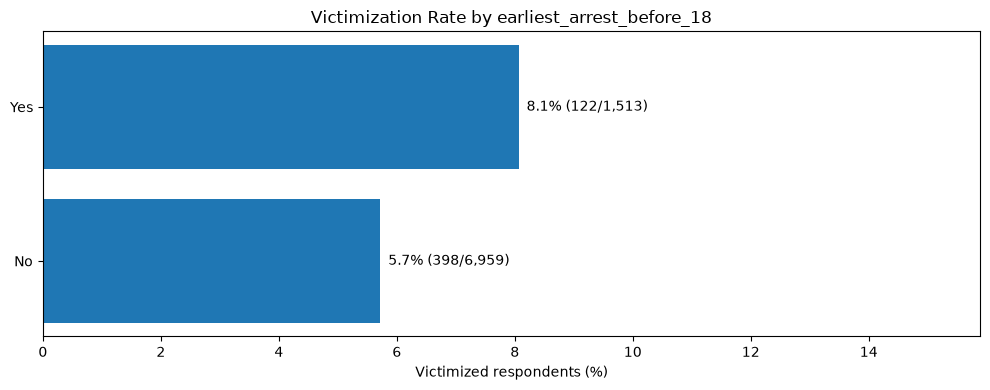

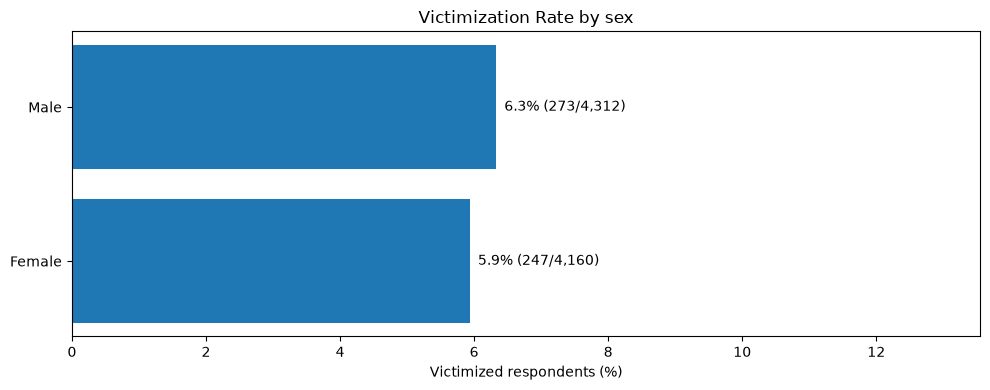

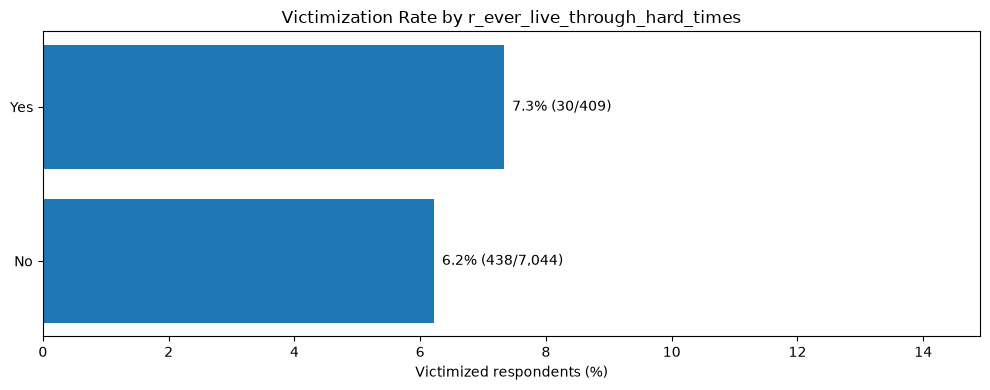

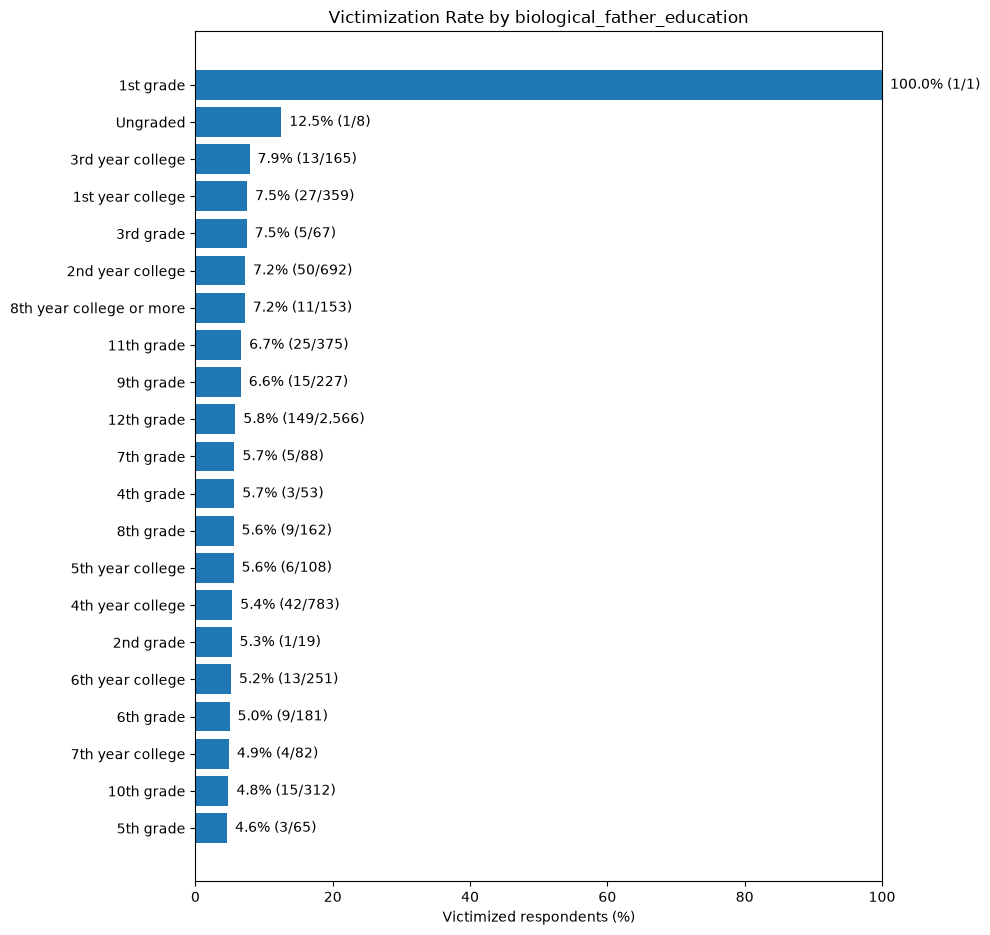

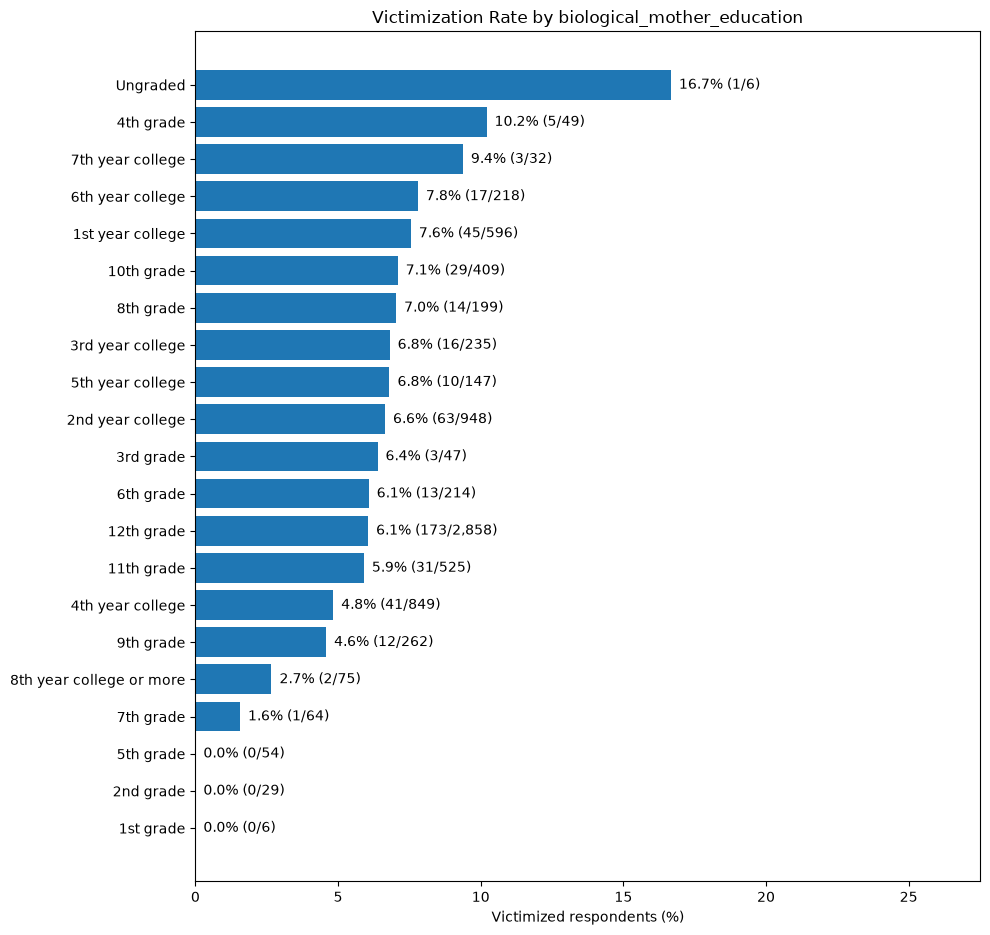

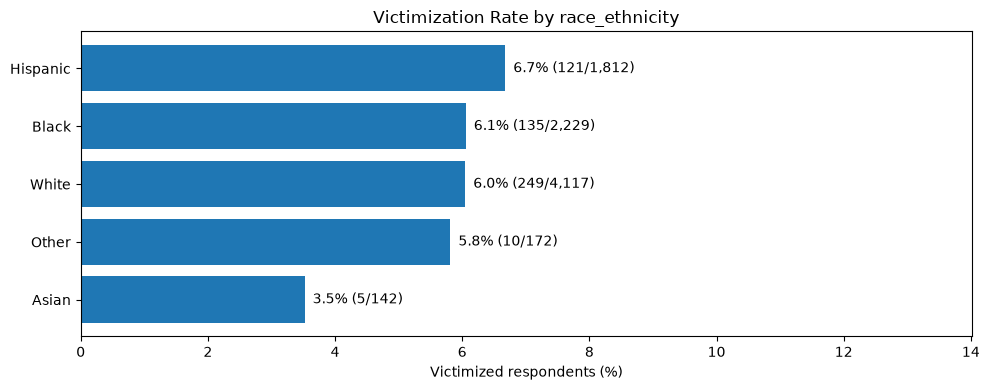

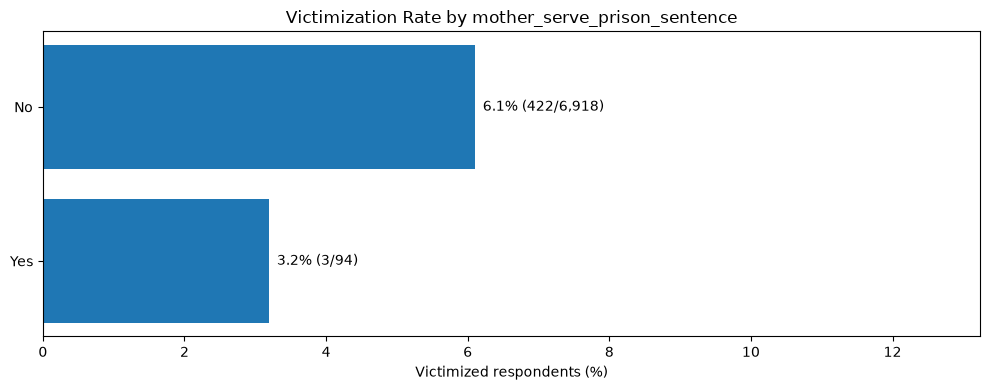

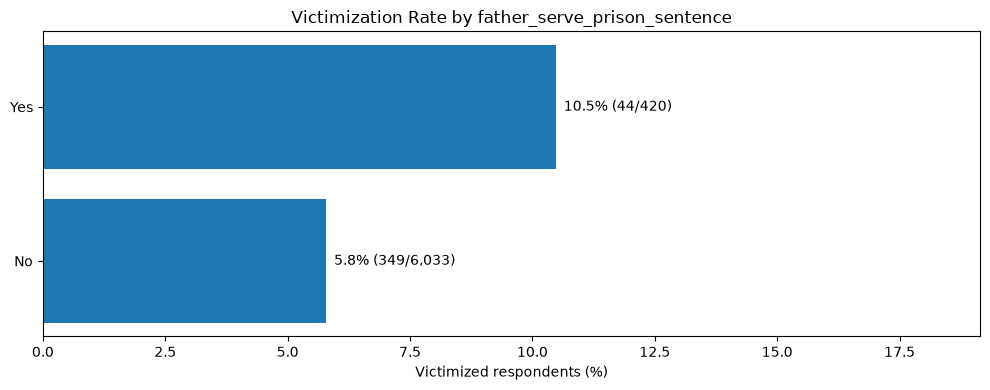

In [13]:
plot_data = data[data[outcome].notna()].copy()

for col in categorical_features:
    # Treat negative numeric survey codes as missing
    if pd.api.types.is_numeric_dtype(plot_data[col]):
        plot_data.loc[plot_data[col] < 0, col] = np.nan

    temp = plot_data[[col, outcome]].dropna(subset=[col]).copy()

    if temp.empty:
        continue

    # Convert numeric response codes to readable labels
    if col in CATEGORY_LABELS:
        temp[col] = temp[col].replace(CATEGORY_LABELS[col])

    summary = (
        temp.groupby(col, observed=True)[outcome]
        .agg(victimized="sum", total="count")
    )

    summary["percent_victimized"] = (
        summary["victimized"] / summary["total"] * 100
    )

    summary = summary.sort_values("percent_victimized")

    fig, ax = plt.subplots(
        figsize=(10, max(4, 0.45 * len(summary)))
    )

    bars = ax.barh(
        summary.index.astype(str),
        summary["percent_victimized"]
    )

    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"  {row['percent_victimized']:.1f}% "
            f"({int(row['victimized']):,}/{int(row['total']):,})",
            va="center"
        )

    ax.set_title(f"Victimization Rate by {col}")
    ax.set_xlabel("Victimized respondents (%)")
    ax.set_ylabel("")
    ax.set_xlim(
        0,
        min(100, summary["percent_victimized"].max() * 1.35 + 5)
    )

    plt.tight_layout()
    plt.show()